# Grad-CAM Analysis of the Custom CNN from Scratch

This notebook visualizes Grad-CAM explanations for the `Custom CNN` model trained from scratch.
The goal is to inspect whether the from-scratch model focuses on clinically meaningful retinal regions and how its attention differs from the transfer learning models.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from torch.utils.data import DataLoader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [2]:
project_root = Path.cwd().resolve()
for candidate in [project_root, *project_root.parents]:
    if (candidate / "src").exists() and (candidate / "configs").exists():
        project_root = candidate
        break

sys.path.insert(0, str(project_root / "src"))

from dr_detection.config import load_yaml_config, resolve_path
from dr_detection.dataset import FundusImageDataset, default_transforms, load_fundus_records
from dr_detection.explainability import generate_gradcam_overlay, get_default_target_layer
from dr_detection.train import build_model

config = load_yaml_config(project_root / "configs" / "custom_cnn_scratch.yaml")
dataset_cfg = config["dataset"]
training_cfg = config["training"]

checkpoint_path = project_root / "models" / "custom_cnn_scratch" / "best_model.pt"
gradcam_dir = project_root / "outputs" / "custom_cnn" / "gradcam"
gradcam_dir.mkdir(parents=True, exist_ok=True)

label_map = {0: "No DR", 1: "DR Present"}

test_records = load_fundus_records(
    csv_path=resolve_path(project_root, dataset_cfg["test_csv_path"]),
    images_dir=resolve_path(project_root, dataset_cfg["test_images_dir"]),
    image_extension=dataset_cfg.get("image_extension", ".png"),
    binary_classification=dataset_cfg.get("binary_classification", True),
)

test_dataset = FundusImageDataset(
    test_records,
    transform=default_transforms(
        image_size=dataset_cfg.get("image_size", 224),
        train=False,
        preprocessing_cfg=dataset_cfg.get("preprocessing"),
    ),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=training_cfg.get("batch_size", 64),
    shuffle=False,
    num_workers=0,
)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

checkpoint = torch.load(checkpoint_path, map_location=device)
model = build_model(
    model_name=checkpoint["model_name"],
    num_classes=checkpoint["num_classes"],
    pretrained=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

target_layer = get_default_target_layer(model, checkpoint["model_name"])

print(f"Checkpoint: {checkpoint_path}")
print(f"Model: {checkpoint['model_name']}")
print(f"Device: {device}")


Checkpoint: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/models/custom_cnn_scratch/best_model.pt
Model: custom_cnn
Device: mps


In [3]:
all_labels = []
all_predictions = []
all_scores = []
all_image_paths = []

with torch.no_grad():
    for images, labels, image_paths in test_loader:
        images = images.to(device)
        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_scores.extend(probabilities[:, 1].cpu().tolist())
        all_image_paths.extend(image_paths)

predictions_df = pd.DataFrame(
    {
        "image_path": all_image_paths,
        "true_label": all_labels,
        "predicted_label": all_predictions,
        "dr_probability": all_scores,
    }
)
predictions_df["true_class"] = predictions_df["true_label"].map(label_map)
predictions_df["predicted_class"] = predictions_df["predicted_label"].map(label_map)

def assign_outcome(row: pd.Series) -> str:
    if row["true_label"] == 1 and row["predicted_label"] == 1:
        return "True Positive"
    if row["true_label"] == 0 and row["predicted_label"] == 0:
        return "True Negative"
    if row["true_label"] == 0 and row["predicted_label"] == 1:
        return "False Positive"
    return "False Negative"

predictions_df["outcome"] = predictions_df.apply(assign_outcome, axis=1)
predictions_df.head()


,image_path,true_label,predicted_label,dr_probability,true_class,predicted_class,outcome
0,/Users/berekebaimuratov/Desktop/Detection of D...,0,0,0.020596,No DR,No DR,True Negative
1,/Users/berekebaimuratov/Desktop/Detection of D...,1,1,0.992471,DR Present,DR Present,True Positive
2,/Users/berekebaimuratov/Desktop/Detection of D...,1,0,0.265650,DR Present,No DR,False Negative
3,/Users/berekebaimuratov/Desktop/Detection of D...,0,0,0.034474,No DR,No DR,True Negative
4,/Users/berekebaimuratov/Desktop/Detection of D...,0,0,0.279043,No DR,No DR,True Negative


**Table 7.1. Number of test images by prediction outcome category for the custom CNN**


In [4]:
outcome_summary = predictions_df["outcome"].value_counts().rename_axis("outcome").reset_index(name="count")
outcome_summary.to_csv(gradcam_dir / "table_7_1_custom_cnn_outcome_summary.csv", index=False)
outcome_summary


,outcome,count
0,True Negative,195
1,True Positive,150
2,False Negative,17
3,False Positive,4


**Figure 7.1. Distribution of prediction outcomes for the custom CNN on the test split**


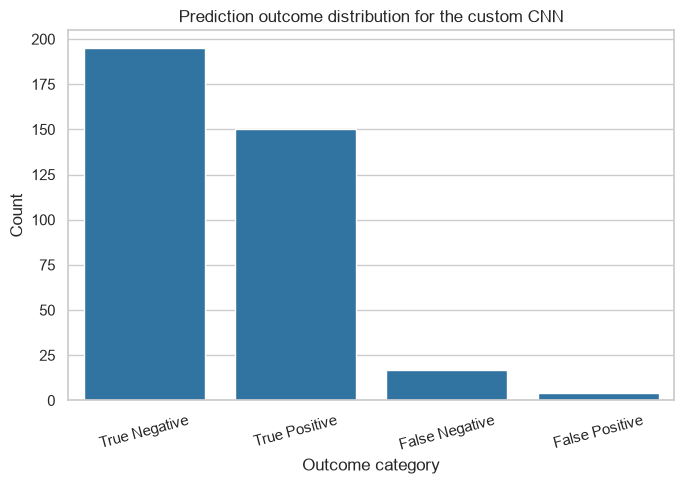

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=outcome_summary, x="outcome", y="count", ax=ax, color="#1f77b4")
ax.set_title("Prediction outcome distribution for the custom CNN")
ax.set_xlabel("Outcome category")
ax.set_ylabel("Count")
plt.xticks(rotation=15)
plt.tight_layout()
fig.savefig(gradcam_dir / "figure_7_1_custom_cnn_outcome_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


**Image 7.1. Grad-CAM examples for correctly predicted DR-positive images by the custom CNN**


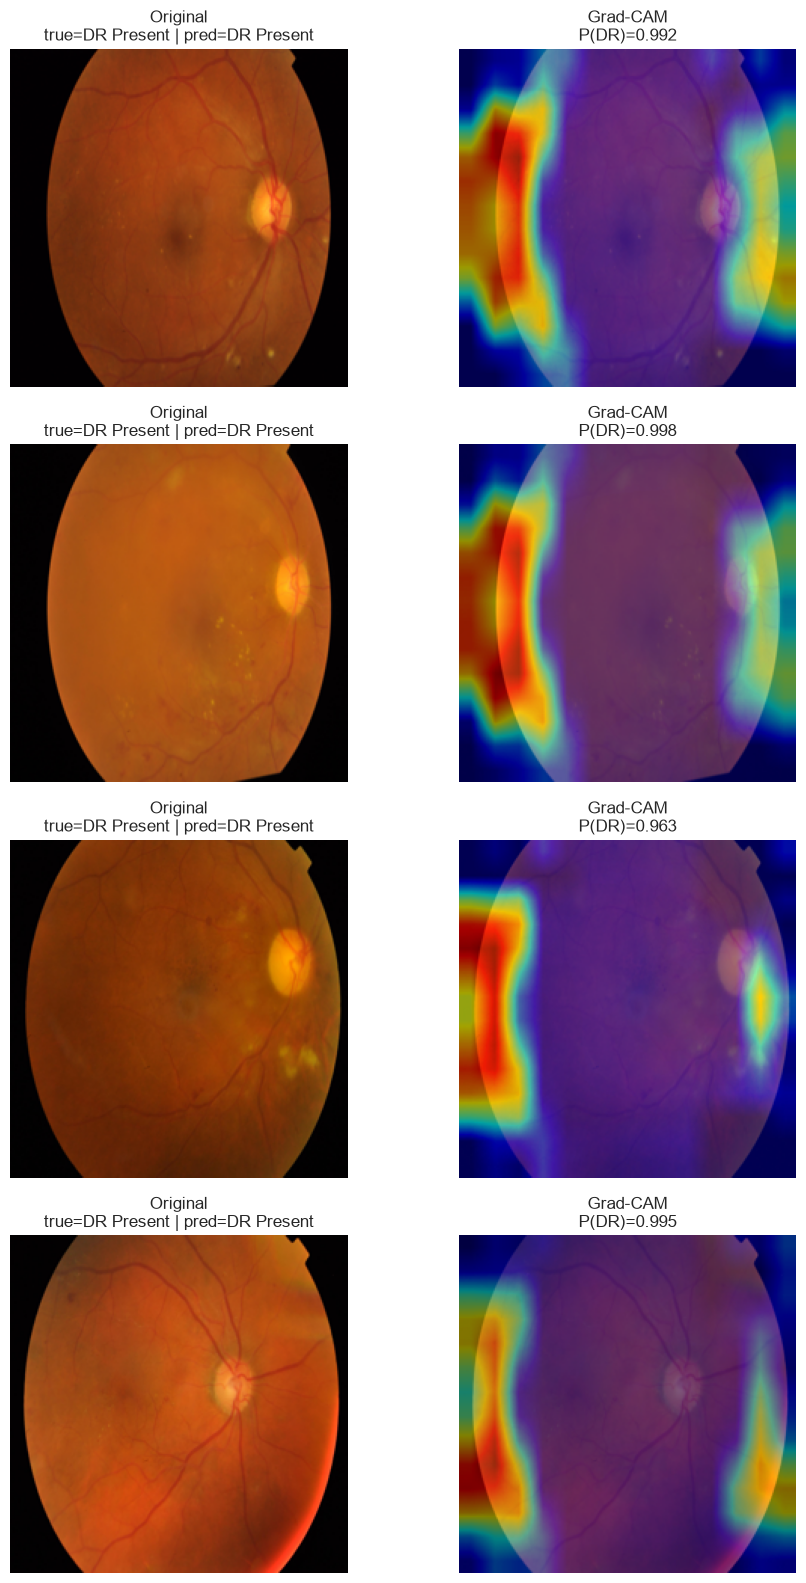

In [6]:
def show_gradcam_examples(df: pd.DataFrame, outcome_name: str, n: int = 4, file_name: str | None = None) -> None:
    subset = df.loc[df["outcome"] == outcome_name].copy().head(n).reset_index(drop=True)
    if subset.empty:
        print(f"No samples found for: {outcome_name}")
        return

    fig, axes = plt.subplots(len(subset), 2, figsize=(10, 4 * len(subset)))
    if len(subset) == 1:
        axes = [axes]

    for row_axes, (_, row) in zip(axes, subset.iterrows()):
        original = Image.open(row["image_path"]).convert("RGB").resize((224, 224))
        overlay = generate_gradcam_overlay(
            model=model,
            target_layer=target_layer,
            image_path=row["image_path"],
            image_size=dataset_cfg.get("image_size", 224),
            target_class=int(row["predicted_label"]),
        )

        row_axes[0].imshow(original)
        row_axes[0].set_title(
            f"Original\ntrue={row['true_class']} | pred={row['predicted_class']}"
        )
        row_axes[0].axis("off")

        row_axes[1].imshow(overlay)
        row_axes[1].set_title(
            f"Grad-CAM\nP(DR)={row['dr_probability']:.3f}"
        )
        row_axes[1].axis("off")

    plt.tight_layout()
    if file_name is not None:
        fig.savefig(gradcam_dir / file_name, dpi=300, bbox_inches="tight")
    plt.show()


show_gradcam_examples(
    predictions_df,
    outcome_name="True Positive",
    n=4,
    file_name="image_7_1_custom_cnn_true_positive_gradcam.png",
)


**Image 7.2. Grad-CAM examples for correctly predicted DR-negative images by the custom CNN**


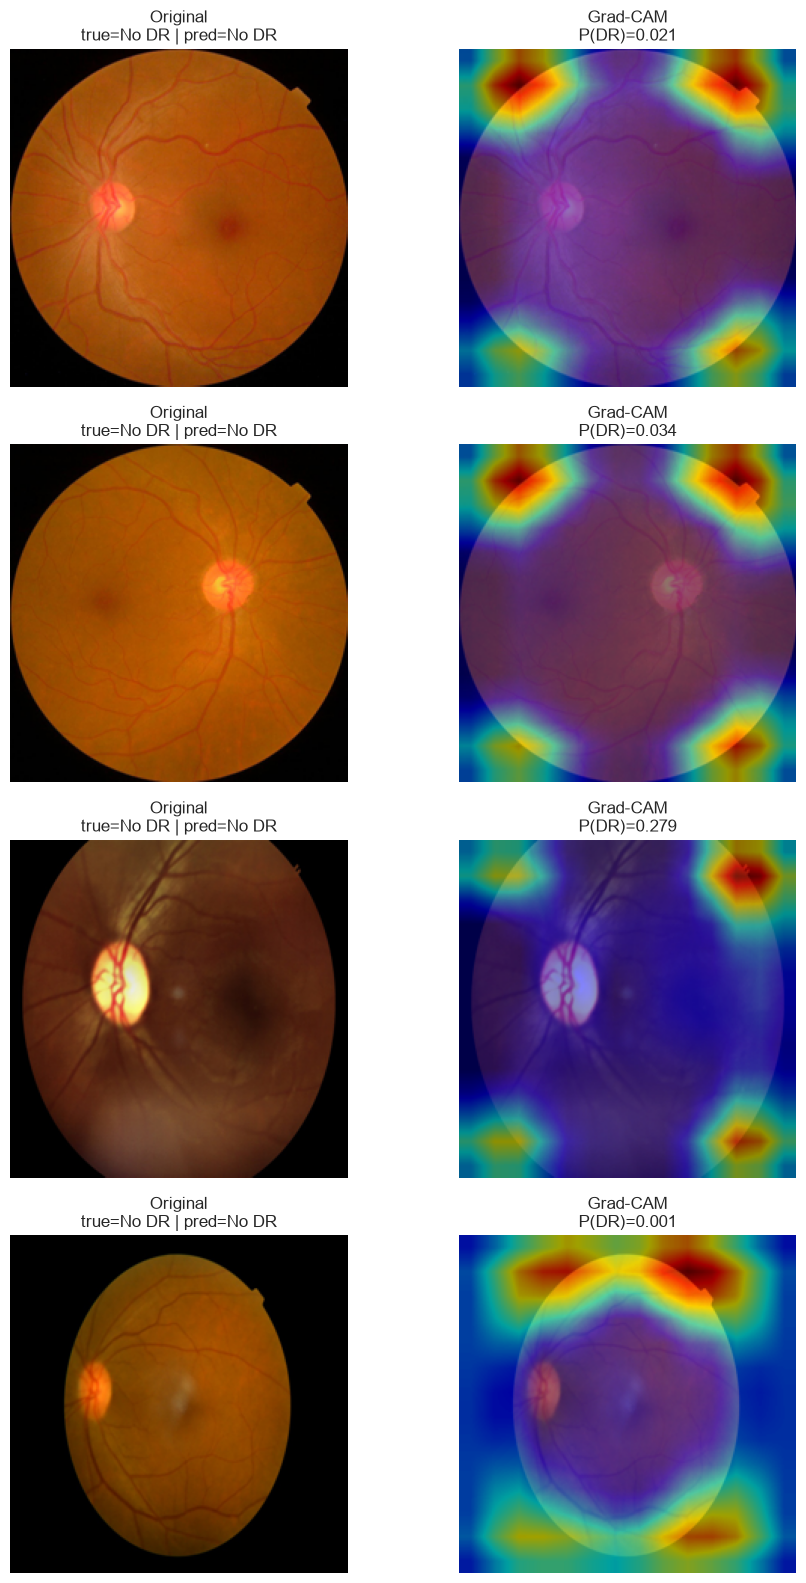

In [7]:
show_gradcam_examples(
    predictions_df,
    outcome_name="True Negative",
    n=4,
    file_name="image_7_2_custom_cnn_true_negative_gradcam.png",
)


**Image 7.3. Grad-CAM examples for false-positive predictions by the custom CNN**


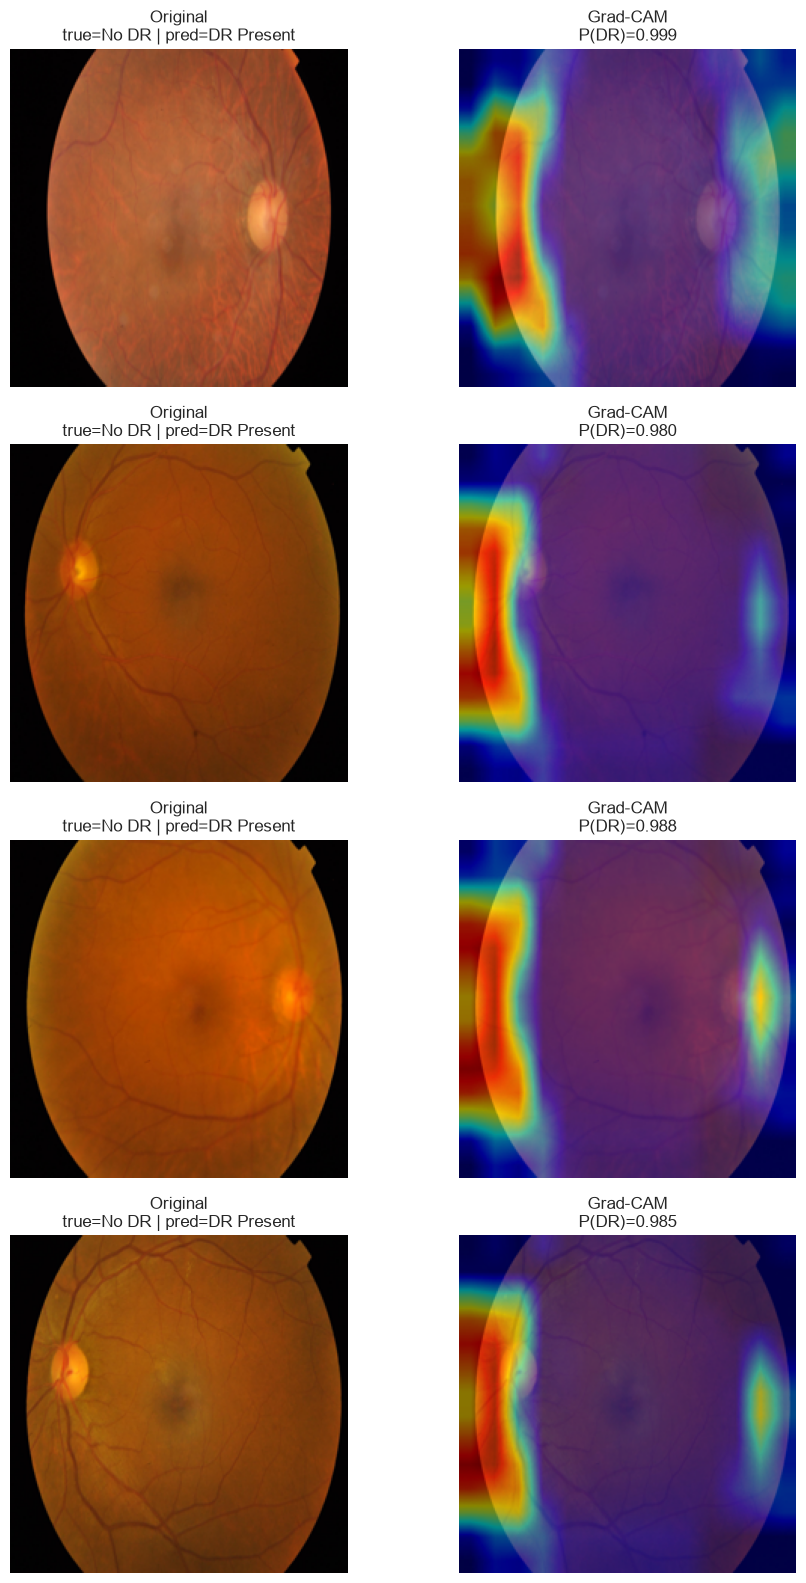

In [8]:
show_gradcam_examples(
    predictions_df,
    outcome_name="False Positive",
    n=4,
    file_name="image_7_3_custom_cnn_false_positive_gradcam.png",
)


**Image 7.4. Grad-CAM examples for false-negative predictions by the custom CNN**


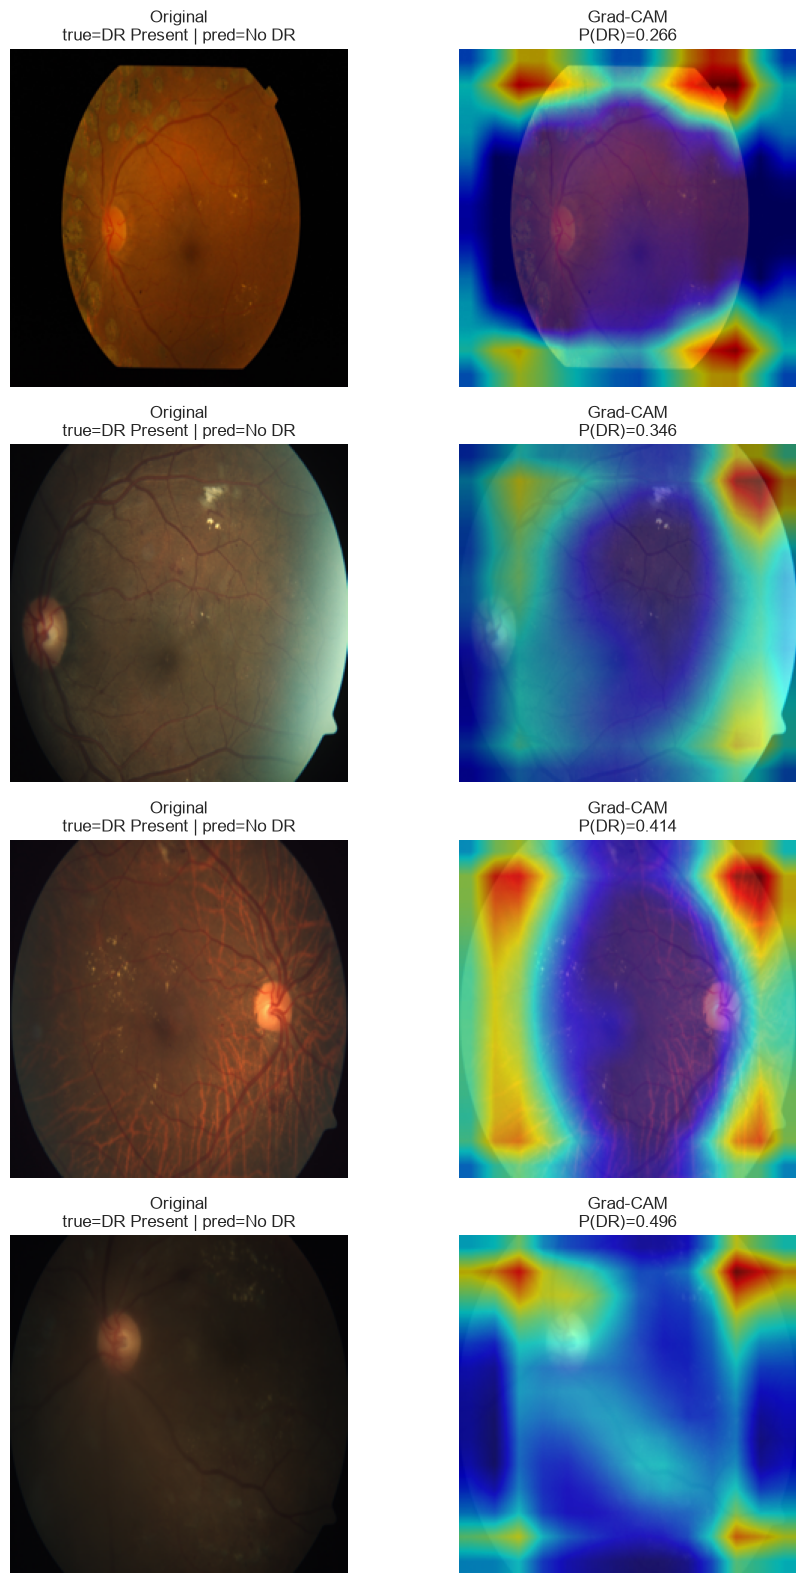

In [9]:
show_gradcam_examples(
    predictions_df,
    outcome_name="False Negative",
    n=4,
    file_name="image_7_4_custom_cnn_false_negative_gradcam.png",
)
